# 學習曲線：增加資料量有沒有用？

模型設定跟 `sign_transformer_ctc3.ipynb` **完全相同**，只改變訓練資料量：
分別用 **25%、50%、75%、100%** 的訓練影片訓練，驗證集與測試集都不變，看效果怎麼隨資料量變化。

- 以**影片 (子資料夾)** 為單位抽樣，同一則新聞的句子不會被拆開
- 抽樣是**巢狀**的：25% 的影片一定包含在 50% 裡，50% 一定包含在 75% 裡，曲線比較平滑
- 100% 預設直接沿用 `predictions_ctc3` 的結果 (設定完全相同)，不用再訓練一次 (`REUSE_FULL_FROM`)
- 每組跑完就把預測存檔；中途中斷的話重新執行，已經完成的組別會自動略過

字典 (`vocab.json`) 與 `norm_masked.npz` 都用完整訓練集計算的版本，讓各組只有「訓練資料量」不同。

**怎麼看結果** (最後的圖表)：
- 新句 CER、新句精確率**從 50% 到 100% 還在明顯改善** → 曲線還沒變平，**增加資料很可能有用**
- **50% 跟 100% 差不多** → 曲線已經變平，再加同類資料效果有限，應該優先處理特徵 (臉部、嘴型) 或縮小任務範圍

總共約需 30～40 分鐘 (25%、50%、75% 三組；資料越少每個 epoch 越快)。

In [1]:
import copy
import csv
import json
import math
import os
import random
import re
import unicodedata
import warnings
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm

warnings.filterwarnings("ignore")
# os.chdir(r"C:\你的專案資料夾\Data Training")

# ================================================================ 實驗設定
SEG_TAG = ""               # 用哪一種切法的資料："" = 原本，"_m0.5" = 寬鬆切法
RUN_TAG = "_lc"            # 學習曲線，checkpoints / predictions 會加上這個後綴

# ================================================================ 路徑設定
LABEL_DIR = Path(r"..\Data Preparation\Phase5-Pause\output\03labels" + SEG_TAG)
SEG_DIR = Path(r"..\Data Preparation\Phase5-Pause\output\03segments" + SEG_TAG)
DATA_DIR = Path(r"data" + SEG_TAG)                   # 跟原本的 notebook 共用
CKPT_DIR = Path(r"checkpoints" + SEG_TAG + RUN_TAG)   # 底下每組一個資料夾：frac_025、frac_050 ...
PRED_DIR = Path(r"predictions" + SEG_TAG + RUN_TAG)   # 同上

# ================================================================ 學習曲線設定
FRACTIONS = [0.25, 0.5, 0.75, 1.0]     # 用多少比例的訓練影片
REUSE_FULL_FROM = "predictions_ctc3"   # 100% 直接沿用 ctc3 的預測 (設定完全相同)；設成 None 就重新訓練
PRED_SPLIT = "test"

# ================================================================ 資料集切分 (DATA_DIR 已經有資料時不會重建)
SPLIT = (0.8, 0.1, 0.1)
SEED = 42
SPECIALS = ["<pad>", "<bos>", "<eos>", "<unk>"]
FLAG_DIMS = [126, 127, 155]
MIN_FREQ = 2

# ================================================================ 資料設定
FRAME_STRIDE = 2
MAX_FRAMES = 300
MAX_TEXT_LEN = 64
SPEED_RANGE = (0.8, 1.2)
NOISE_STD = 0.05           # 只加在有偵測到的座標上，旗標不加

# ================================================================ 新增：缺漏遮罩與資料增強
NORM_FILE = "norm_masked.npz"   # 只用有偵測到的格計算的 norm (存在 DATA_DIR，不覆蓋 norm.npz)
AUGMENT = True             # False = 只做變速與雜訊 (跟之前一樣)，方便單獨比較遮罩的效果
ROTATE_DEG = 10            # 隨機旋轉 ±幾度 (pose 與手形一起轉，模擬鏡頭微微傾斜)
SCALE_RANGE = (0.9, 1.1)   # pose 隨機縮放 (模擬人離鏡頭遠近)
SHIFT = 0.05               # pose 隨機平移 (畫面寬高的比例)
TIME_MASK_N = 2            # 每句隨機遮掉幾段
TIME_MASK_MAX = 0.1        # 每段最長佔整句的比例

# ================================================================ 模型設定
D_MODEL = 256
N_HEADS = 4
ENC_LAYERS = 4
DEC_LAYERS = 2             # 原本 3
FF_DIM = 1024
DROPOUT = 0.3

# ================================================================ 新增：CTC 與 decoder 遮字
CTC_WEIGHT = 0.5           # 總損失裡 CTC 佔的比例 (同 _ctc；_ctc2 的 0.7 沒有比較好)
WORD_DROPOUT = 0.25        # 訓練時 decoder 輸入有多少比例的字換成 <unk>
NO_REPEAT_NGRAM = 4        # 解碼時禁止同樣的 N 字片段出現第二次 (0 = 不限制)；設 4 而不是 3，避免擋掉「10000」這類數字
MAX_CHAR_RUN = 4           # 同一個字最多連續出現幾次 (擋「天天天天天」；4 才不會擋到「10000」)

# ================================================================ 訓練設定
BATCH_SIZE = 32
EPOCHS = 150
LR = 3e-4
WEIGHT_DECAY = 0.05
WARMUP_EPOCHS = 5
LABEL_SMOOTHING = 0.1
EARLY_STOP_ON = "ce"       # 用哪個 val 損失選模型、判斷提前停止："ce" = 只看翻譯 (同 _ctc)，"total" = 翻譯 + CTC (_ctc2)
PATIENCE = 15              # 連續幾個 epoch 沒進步就停止 (_ctc 是 10；資料增強會讓收斂變慢，所以放寬一點)
VAL_CER_EVERY = 5

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"
PAD, BOS, EOS, UNK = 0, 1, 2, 3
BLANK = PAD                # CTC 的空白符號借用 <pad> (它不會出現在答案裡)
print("device:", DEVICE)

device: cuda


## DATASET
跟 ctc3 相同：沿用 `data/` 的資料切分與字典，`norm_masked.npz` 已經存在就直接沿用。

In [2]:
if all((DATA_DIR / name).exists() for name in ("train.csv", "val.csv", "test.csv", "vocab.json", "norm.npz")):
    print(f"沿用 {DATA_DIR} 裡現有的資料切分、字典與 norm")
else:
    print(f"{DATA_DIR} 沒有完整資料，重新建立")
    groups = {}
    for txt in sorted(LABEL_DIR.glob("*/*/*.txt")):
        group = txt.parent.relative_to(LABEL_DIR)
        for line in txt.read_text(encoding="utf-8").splitlines():
            name, _, text = line.partition(": ")
            if text.strip():
                groups.setdefault(group.as_posix(), []).append(((group / f"{name}.npy").as_posix(), text.strip()))

    keys = sorted(groups)
    random.Random(SEED).shuffle(keys)
    n_train, n_val = round(len(keys) * SPLIT[0]), round(len(keys) * SPLIT[1])
    splits = {"train": keys[:n_train], "val": keys[n_train:n_train + n_val], "test": keys[n_train + n_val:]}

    DATA_DIR.mkdir(parents=True, exist_ok=True)
    rows = {}
    for split, split_keys in splits.items():
        rows[split] = [row for key in sorted(split_keys) for row in groups[key]]
        with (DATA_DIR / f"{split}.csv").open("w", newline="", encoding="utf-8-sig") as f:
            writer = csv.writer(f)
            writer.writerow(("path", "text"))
            writer.writerows(rows[split])

    freq = Counter(c for _, text in rows["train"] for c in text)
    chars = sorted(c for c, n in freq.items() if n >= MIN_FREQ)
    (DATA_DIR / "vocab.json").write_text(json.dumps(SPECIALS + chars, ensure_ascii=False), encoding="utf-8")

    total, total_sq, count = np.zeros(156), np.zeros(156), 0
    for path, _ in tqdm(rows["train"], desc="norm"):
        arr = np.load(SEG_DIR / path).astype(np.float64)
        total += arr.sum(0)
        total_sq += (arr ** 2).sum(0)
        count += len(arr)
    mean = total / count
    std = np.sqrt(np.maximum(total_sq / count - mean ** 2, 0)) + 1e-6
    mean[FLAG_DIMS], std[FLAG_DIMS] = 0.0, 1.0
    np.savez(DATA_DIR / "norm.npz", mean=mean.astype(np.float32), std=std.astype(np.float32))

for split in ("train", "val", "test"):
    with (DATA_DIR / f"{split}.csv").open(encoding="utf-8-sig", newline="") as f:
        print(f"{split}: {sum(1 for _ in csv.DictReader(f))} 句")
print("字元數:", len(json.loads((DATA_DIR / "vocab.json").read_text(encoding="utf-8"))) - len(SPECIALS))

# ---------------------------------------------------------------- 特徵位置與缺漏遮罩
LEFT, RIGHT, POSE = slice(0, 63), slice(63, 126), slice(128, 155)
LEFT_FLAG, RIGHT_FLAG, POSE_FLAG = 126, 127, 155


def valid_mask(arr):
    """(T, 156) 的 bool：每一維是不是真的有偵測到。旗標本身永遠算有效。"""
    m = np.ones(arr.shape, dtype=bool)
    m[:, LEFT] = arr[:, [LEFT_FLAG]] > 0.5
    m[:, RIGHT] = arr[:, [RIGHT_FLAG]] > 0.5
    point_ok = (arr[:, POSE].reshape(-1, 9, 3)[:, :, 2] > 0) & (arr[:, [POSE_FLAG]] > 0.5)   # 信心值 0 = 這個點沒偵測到
    m[:, POSE] = np.repeat(point_ok, 3, axis=1)
    return m


if (DATA_DIR / NORM_FILE).exists():
    print(f"沿用 {DATA_DIR / NORM_FILE}")
else:
    with (DATA_DIR / "train.csv").open(encoding="utf-8-sig", newline="") as f:
        train_paths = [row["path"] for row in csv.DictReader(f)]
    total, total_sq, count = np.zeros(156), np.zeros(156), np.zeros(156)
    for path in tqdm(train_paths, desc="masked norm"):
        arr = np.load(SEG_DIR / path).astype(np.float64)
        m = valid_mask(arr)
        arr = np.where(m, arr, 0.0)
        total += arr.sum(0)
        total_sq += (arr ** 2).sum(0)
        count += m.sum(0)
    mean = total / np.maximum(count, 1)
    std = np.sqrt(np.maximum(total_sq / np.maximum(count, 1) - mean ** 2, 0)) + 1e-6
    mean[FLAG_DIMS], std[FLAG_DIMS] = 0.0, 1.0
    np.savez(DATA_DIR / NORM_FILE, mean=mean.astype(np.float32), std=std.astype(np.float32),
             valid_ratio=(count / count.max()).astype(np.float32))
    print(f"已存成 {DATA_DIR / NORM_FILE}")

ratio = np.load(DATA_DIR / NORM_FILE)["valid_ratio"]
print(f"訓練集偵測率：左手 {ratio[0]:.1%}、右手 {ratio[63]:.1%}、左腕 {ratio[128 + 3 * 5]:.1%}、右腕 {ratio[128 + 3 * 6]:.1%}")

沿用 data 裡現有的資料切分、字典與 norm
train: 17901 句
val: 2234 句
test: 2265 句
字元數: 2662
沿用 data\norm_masked.npz
訓練集偵測率：左手 70.1%、右手 93.6%、左腕 99.2%、右腕 99.7%


In [3]:
def load_vocab():
    return json.loads((DATA_DIR / "vocab.json").read_text(encoding="utf-8"))


def augment_geometry(x):
    """隨機旋轉 (pose 與手形一起轉)、pose 縮放與平移。輸入是還沒標準化的原始座標。"""
    x = x.copy()
    T = len(x)
    angle = np.deg2rad(np.random.uniform(-ROTATE_DEG, ROTATE_DEG))
    c, s = np.cos(angle), np.sin(angle)
    rot = np.array([[c, -s], [s, c]], dtype=np.float32)

    pose = x[:, POSE].reshape(T, 9, 3)
    ok = pose[:, :, 2:] > 0
    xy = (pose[:, :, :2] - 0.5) @ rot.T * np.random.uniform(*SCALE_RANGE) + 0.5 \
        + np.random.uniform(-SHIFT, SHIFT, 2).astype(np.float32)
    pose[:, :, :2] = np.where(ok, xy, 0.0)
    x[:, POSE] = pose.reshape(T, -1)

    hands = x[:, :126].reshape(T, 2, 21, 3)          # 手形已經以手腕為原點，直接轉 (沒偵測到的是 0，轉完還是 0)
    hands[..., :2] = hands[..., :2] @ rot.T
    x[:, :126] = hands.reshape(T, -1)
    return x


def time_mask(x):
    """隨機把幾段連續的格整段設成 0 (含旗標)，模擬遮擋或漏偵測。"""
    T = len(x)
    for _ in range(TIME_MASK_N):
        width = np.random.randint(0, max(1, int(T * TIME_MASK_MAX)) + 1)
        if width:
            start = np.random.randint(0, T - width + 1)
            x[start:start + width] = 0.0
    return x


class SignDataset(Dataset):
    def __init__(self, split, vocab, train=False):
        with (DATA_DIR / f"{split}.csv").open(encoding="utf-8-sig", newline="") as f:
            self.rows = [(row["path"], row["text"]) for row in csv.DictReader(f)]
        self.stoi = {c: i for i, c in enumerate(vocab)}
        norm = np.load(DATA_DIR / NORM_FILE)
        self.mean, self.std = norm["mean"], norm["std"]
        self.train = train
        # 快取「原始值」(只做取樣)，資料增強要在標準化之前做
        self.cache = [
            np.ascontiguousarray(np.load(SEG_DIR / path).astype(np.float32)[::FRAME_STRIDE])
            for path, _ in tqdm(self.rows, desc=f"load {split}")
        ]

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        text = self.rows[i][1]
        raw = self.cache[i]
        if self.train:
            n = max(1, round(len(raw) * random.uniform(*SPEED_RANGE)))
            raw = raw[np.linspace(0, len(raw) - 1, n).round().astype(int)]
            if AUGMENT:
                raw = augment_geometry(raw)

        mask = valid_mask(raw)
        x = np.where(mask, (raw - self.mean) / self.std, 0.0).astype(np.float32)   # 沒偵測到的一律 0

        if self.train:
            noise = np.random.normal(0, NOISE_STD, x.shape).astype(np.float32)
            noise[:, FLAG_DIMS] = 0.0
            x = x + noise * mask                       # 雜訊只加在有偵測到的座標
            if AUGMENT:
                x = time_mask(x)
        x = x[:MAX_FRAMES]
        ids = [BOS] + [self.stoi.get(c, UNK) for c in text[:MAX_TEXT_LEN - 2]] + [EOS]
        return torch.from_numpy(np.ascontiguousarray(x)), torch.tensor(ids)


def collate(batch):
    xs, ys = zip(*batch)
    src = nn.utils.rnn.pad_sequence(xs, batch_first=True)
    lengths = torch.tensor([len(x) for x in xs])
    src_mask = torch.arange(src.size(1))[None, :] >= lengths[:, None]     # True = padding
    tgt = nn.utils.rnn.pad_sequence(ys, batch_first=True, padding_value=PAD)
    return src, src_mask, tgt

In [4]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=2000):
        super().__init__()
        pos = torch.arange(max_len).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe)

    def forward(self, x):
        return x + self.pe[:x.size(1)]


class SignTransformerCTC(nn.Module):
    def __init__(self, vocab_size, feat_dim=156):
        super().__init__()
        self.src_proj = nn.Sequential(
            nn.Linear(feat_dim, D_MODEL), nn.LayerNorm(D_MODEL), nn.GELU(),
            nn.Dropout(DROPOUT), nn.Linear(D_MODEL, D_MODEL),
        )
        self.tgt_emb = nn.Embedding(vocab_size, D_MODEL, padding_idx=PAD)
        self.pos = PositionalEncoding(D_MODEL)
        self.transformer = nn.Transformer(
            D_MODEL, N_HEADS, ENC_LAYERS, DEC_LAYERS, FF_DIM, DROPOUT,
            batch_first=True, norm_first=True,
        )
        self.out = nn.Linear(D_MODEL, vocab_size)
        # 新增：encoder 每個 frame 直接預測字 (含 blank)
        self.ctc_norm = nn.LayerNorm(D_MODEL)
        self.ctc_out = nn.Linear(D_MODEL, vocab_size)

    def encode(self, src, src_mask):
        return self.transformer.encoder(self.pos(self.src_proj(src)), src_key_padding_mask=src_mask)

    def ctc_logits(self, memory):
        return self.ctc_out(self.ctc_norm(memory))

    def decode(self, tgt, memory, src_mask):
        L = tgt.size(1)
        causal = torch.triu(torch.ones(L, L, dtype=torch.bool, device=tgt.device), 1)
        h = self.transformer.decoder(
            self.pos(self.tgt_emb(tgt) * math.sqrt(D_MODEL)), memory,
            tgt_mask=causal, tgt_key_padding_mask=tgt == PAD, memory_key_padding_mask=src_mask,
        )
        return self.out(h)

    def forward(self, src, src_mask, tgt_in):
        """回傳 (decoder logits, CTC logits)。訓練時 decoder 輸入會隨機遮字。"""
        memory = self.encode(src, src_mask)
        if self.training and WORD_DROPOUT > 0:
            drop = (torch.rand(tgt_in.shape, device=tgt_in.device) < WORD_DROPOUT) & (tgt_in > UNK)
            tgt_in = tgt_in.masked_fill(drop, UNK)          # <bos>、<pad> 不遮
        return self.decode(tgt_in, memory, src_mask), self.ctc_logits(memory)

In [5]:
def compute_loss(model, src, src_mask, tgt, ce_criterion, ctc_criterion):
    """回傳 (總損失, 翻譯損失, CTC 損失)。"""
    logits, ctc_logits = model(src, src_mask, tgt[:, :-1])
    ce = ce_criterion(logits.reshape(-1, logits.size(-1)), tgt[:, 1:].reshape(-1))

    # CTC 的答案 = 去掉 <bos> / <eos> / <pad> 的字
    gold = tgt[:, 1:]
    keep = (gold != PAD) & (gold != EOS)
    log_probs = ctc_logits.float().log_softmax(-1).transpose(0, 1)       # (T, N, C)
    input_lengths = (~src_mask).sum(1)
    ctc = ctc_criterion(log_probs, gold[keep], input_lengths, keep.sum(1))
    return (1 - CTC_WEIGHT) * ce + CTC_WEIGHT * ctc, ce, ctc


def run_epoch(model, loader, ce_criterion, ctc_criterion, optimizer=None, scheduler=None, scaler=None,
              zero_input=False):
    """回傳 (平均翻譯損失, 平均 CTC 損失)，翻譯損失以字數加權。"""
    train = optimizer is not None
    model.train(train)
    ce_total = ctc_total = 0.0
    count = n_batch = 0
    for src, src_mask, tgt in loader:
        if zero_input:
            src = torch.zeros_like(src)
        src, src_mask, tgt = src.to(DEVICE), src_mask.to(DEVICE), tgt.to(DEVICE)
        with torch.set_grad_enabled(train), torch.autocast(DEVICE, enabled=USE_AMP):
            loss, ce, ctc = compute_loss(model, src, src_mask, tgt, ce_criterion, ctc_criterion)
        if train:
            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            if scheduler is not None:
                scheduler.step()
        n = (tgt[:, 1:] != PAD).sum().item()
        ce_total += ce.item() * n
        count += n
        ctc_total += ctc.item()
        n_batch += 1
    return ce_total / count, ctc_total / max(1, n_batch)

In [6]:
def banned_tokens(seq, n, max_run=0):
    """seq 再接哪些字會讓某個 n 字片段第二次出現，或讓同一個字連續超過 max_run 次。"""
    banned = []
    if n > 0 and len(seq) >= n - 1:
        prefix = tuple(seq[len(seq) - (n - 1):]) if n > 1 else ()
        banned = [seq[i + n - 1] for i in range(len(seq) - n + 1) if tuple(seq[i:i + n - 1]) == prefix]
    if max_run > 0 and len(seq) >= max_run and len(set(seq[-max_run:])) == 1:
        banned.append(seq[-1])
    return banned


@torch.no_grad()
def greedy_decode(model, src, src_mask):
    memory = model.encode(src, src_mask)
    ys = torch.full((src.size(0), 1), BOS, dtype=torch.long, device=src.device)
    done = torch.zeros(src.size(0), dtype=torch.bool, device=src.device)
    for _ in range(MAX_TEXT_LEN - 1):
        logits = model.decode(ys, memory, src_mask)[:, -1].float()
        if NO_REPEAT_NGRAM > 0 or MAX_CHAR_RUN > 0:
            for b, seq in enumerate(ys[:, 1:].tolist()):
                banned = banned_tokens(seq, NO_REPEAT_NGRAM, MAX_CHAR_RUN)
                if banned:
                    logits[b, banned] = float("-inf")
        next_tok = logits.argmax(-1)
        next_tok[done] = PAD
        ys = torch.cat([ys, next_tok[:, None]], dim=1)
        done |= next_tok == EOS
        if done.all():
            break
    return ys[:, 1:].tolist()


@torch.no_grad()
def ctc_greedy_decode(model, src, src_mask):
    """CTC 直接解碼：每個 frame 取最大值 → 合併連續重複 → 去掉 blank。"""
    best = model.ctc_logits(model.encode(src, src_mask)).argmax(-1).masked_fill(src_mask, BLANK)
    out = []
    for row in best.tolist():
        ids, prev = [], BLANK
        for t in row:
            if t != prev and t not in (BLANK, BOS, EOS):
                ids.append(t)
            prev = t
        out.append(ids + [EOS])
    return out


def ids_to_text(ids, vocab):
    chars = []
    for i in ids:
        if i in (EOS, PAD):
            break
        chars.append("□" if i == UNK else vocab[i])
    return "".join(chars)


def edit_distance(a, b):
    row = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        prev, row[0] = row[0], i
        for j, cb in enumerate(b, 1):
            prev, row[j] = row[j], min(row[j] + 1, row[j - 1] + 1, prev + (ca != cb))
    return row[-1]


def char_error_rate(preds, refs):
    """字元錯誤率：編輯距離總和 ÷ 正確答案總字數，越低越好。"""
    return sum(edit_distance(p, r) for p, r in zip(preds, refs)) / max(1, sum(len(r) for r in refs))


def predict_loader(model, loader, vocab, decoder=greedy_decode):
    model.eval()
    preds = []
    for src, src_mask, _ in loader:
        with torch.autocast(DEVICE, enabled=USE_AMP):
            out = decoder(model, src.to(DEVICE), src_mask.to(DEVICE))
        preds += [ids_to_text(ids, vocab) for ids in out]
    return preds

## 評估函式
跟 ctc3 相同。

In [7]:
# 迴圈 = 同一個字連續 5 次以上，或同一段 2~4 字連續 3 次以上 (「5000」「999」「111年」不算)
LOOP_RE = re.compile(r"(.)\1{4,}|(.{2,4}?)\2{2,}")


def pad(text, width, left=True):
    """依顯示寬度補空白 (中文字佔 2 格)，讓表格對齊。"""
    w = sum(2 if unicodedata.east_asian_width(ch) in "WF" else 1 for ch in str(text))
    space = " " * max(0, width - w)
    return f"{text}{space}" if left else f"{space}{text}"


def table_row(label, values, label_width=24, width=12):
    cells = [pad("" if v is None else (f"{v:.3f}" if isinstance(v, float) else v), width, left=False) for v in values]
    return pad(label, label_width) + "".join(cells)


def clean_repeats(text):
    """「中國中國中國中國」→「中國」"""
    return LOOP_RE.sub(lambda m: m.group(1) or m.group(2), text)


def char_prf(preds, refs):
    """不看順序的字元精確率、召回率、F1。"""
    hit = n_pred = n_ref = 0
    for p, r in zip(preds, refs):
        hit += sum((Counter(p) & Counter(r)).values())
        n_pred, n_ref = n_pred + len(p), n_ref + len(r)
    prec, rec = hit / max(1, n_pred), hit / max(1, n_ref)
    return prec, rec, 2 * prec * rec / max(1e-9, prec + rec)


def shuffled(preds, groups=None, seed=SEED):
    """打亂預測跟答案的配對。groups 不是 None 時只在同一組 (同一則新聞) 裡打亂。"""
    rng = random.Random(seed)
    if groups is None:
        out = preds[:]
        rng.shuffle(out)
        return out
    out, by_group = preds[:], defaultdict(list)
    for i, g in enumerate(groups):
        by_group[g].append(i)
    for idx in by_group.values():
        perm = idx[:]
        rng.shuffle(perm)
        for a, b in zip(idx, perm):
            out[a] = preds[b]
    return out


def evaluate(pred_csv, train_csv, verbose=True):
    """回傳評估結果 dict；verbose=True 時印出表格。"""
    with Path(pred_csv).open(encoding="utf-8-sig", newline="") as f:
        rows = list(csv.DictReader(f))
    with Path(train_csv).open(encoding="utf-8-sig", newline="") as f:
        train_freq = Counter(row["text"] for row in csv.DictReader(f))

    paths = [r["path"] for r in rows]
    refs = [r["target"] for r in rows]
    raw = [r["prediction"] for r in rows]
    preds = [clean_repeats(p) for p in raw]
    clips = [p.rsplit("_s", 1)[0] for p in paths]
    seen = [train_freq[r] > 0 for r in refs]
    most_common = train_freq.most_common(1)[0][0]

    def sub(mask):
        idx = [i for i, m in enumerate(mask) if m]
        return [preds[i] for i in idx], [refs[i] for i in idx]

    new_p, new_r = sub([not s for s in seen])
    old_p, old_r = sub(seen)
    res = {
        "n": len(refs),
        "n_new": len(new_r),
        "loop_rate": sum(p != c for p, c in zip(raw, preds)) / len(raw),
        "unique_rate": len(set(raw)) / len(raw),
        "cer_raw": char_error_rate(raw, refs),
        "cer": char_error_rate(preds, refs),
        "cer_seen": char_error_rate(old_p, old_r) if old_r else float("nan"),
        "cer_new": char_error_rate(new_p, new_r) if new_r else float("nan"),
        "prf": char_prf(preds, refs),
        "prf_new": char_prf(new_p, new_r) if new_r else (float("nan"),) * 3,
        "base_empty": 1.0,
        "base_const": char_error_rate([most_common] * len(refs), refs),
        "base_shuffle": char_error_rate(shuffled(preds), refs),
        "base_shuffle_clip": char_error_rate(shuffled(preds, clips), refs),
        "prf_shuffle": char_prf(shuffled(preds), refs),
        "prf_shuffle_clip": char_prf(shuffled(preds, clips), refs),
    }
    if not verbose:
        return res

    print(f"{pred_csv}：{res['n']} 句，其中 {res['n_new']} 句 ({res['n_new'] / res['n']:.0%}) 沒在訓練集出現過")
    print(f"不同的預測：{res['unique_rate']:.0%}，有重複迴圈：{res['loop_rate']:.1%}\n")
    print(table_row("", ["CER", "字元精確率", "字元召回率"]))
    print(table_row("模型 (原始輸出)", [res["cer_raw"]]))
    print(table_row("模型 (去除重複迴圈)", [res["cer"], *res["prf"][:2]]))
    print(table_row("  └ 套句 (訓練集有)", [res["cer_seen"]]))
    print(table_row("  └ 新句 (訓練集沒有)", [res["cer_new"], *res["prf_new"][:2]]))
    print("-" * 60)
    print(table_row("基準：空字串", [res["base_empty"]]))
    print(table_row("基準：固定輸出最常見句", [res["base_const"]]))
    print(table_row("基準：全部打亂配對", [res["base_shuffle"], *res["prf_shuffle"][:2]]))
    print(table_row("基準：同則新聞內打亂", [res["base_shuffle_clip"], *res["prf_shuffle_clip"][:2]]))
    return res

## 訓練函式
跟 ctc3 的 Train 完全相同，只是包成函式，讓每組資料量重複使用。

In [8]:
def train_model(train_set, ckpt_dir, desc):
    """用 ctc3 的設定訓練一個模型，best.pt 存到 ckpt_dir。回傳 (最佳 epoch, 最佳 val 翻譯損失, history)。"""
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    train_loader = DataLoader(train_set, BATCH_SIZE, shuffle=True, collate_fn=collate)
    model = SignTransformerCTC(len(vocab)).to(DEVICE)
    ce_criterion = nn.CrossEntropyLoss(ignore_index=PAD, label_smoothing=LABEL_SMOOTHING)
    ctc_criterion = nn.CTCLoss(blank=BLANK, zero_infinity=True)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    total_steps, warmup = EPOCHS * len(train_loader), WARMUP_EPOCHS * len(train_loader)
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer,
        lambda step: step / warmup if step < warmup
        else 0.5 * (1 + math.cos(math.pi * (step - warmup) / max(1, total_steps - warmup))),
    )
    scaler = torch.amp.GradScaler(enabled=USE_AMP)

    ckpt_dir.mkdir(parents=True, exist_ok=True)
    history = []
    best_loss, best_epoch, stale = float("inf"), 0, 0
    bar = tqdm(range(1, EPOCHS + 1), desc=desc)
    for epoch in bar:
        train_ce, train_ctc = run_epoch(model, train_loader, ce_criterion, ctc_criterion, optimizer, scheduler, scaler)
        with torch.no_grad():
            val_ce, val_ctc = run_epoch(model, val_loader, ce_criterion, ctc_criterion)
        history.append((train_ce, val_ce, train_ctc, val_ctc))

        val_total = (1 - CTC_WEIGHT) * val_ce + CTC_WEIGHT * val_ctc
        score = val_total if EARLY_STOP_ON == "total" else val_ce
        if score < best_loss:
            best_loss, best_epoch, stale = score, epoch, 0
            torch.save(model.state_dict(), ckpt_dir / "best.pt")
        else:
            stale += 1
        bar.set_postfix(train=f"{train_ce:.3f}", val=f"{val_ce:.3f}", ctc=f"{val_ctc:.2f}", best=f"{best_loss:.3f}")
        if stale >= PATIENCE:
            break

    model.load_state_dict(torch.load(ckpt_dir / "best.pt", map_location=DEVICE))
    return model, best_epoch, history[best_epoch - 1][1], history


def save_predictions(model, path, decoder):
    preds = predict_loader(model, test_loader, vocab, decoder)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", newline="", encoding="utf-8-sig") as f:
        writer = csv.writer(f)
        writer.writerow(("path", "target", "prediction"))
        writer.writerows((p, ref, pred) for (p, ref), pred in zip(test_set.rows, preds))

## 跑學習曲線
每組的結果存在 `predictions_lc/frac_025/` 這類資料夾：
`test_predictions.csv` (decoder)、`test_predictions_ctc.csv` (CTC 直接解碼)、`train.csv` (這組用到的訓練句子)、`run_info.json` (最佳 epoch 等)。

In [9]:
def video_of(path):
    """「2/10/000641_001738_s00.npy」→「2/10」(part/子資料夾 = 一支原始影片)"""
    return path.rsplit("/", 1)[0]


vocab = load_vocab()
full_train = SignDataset("train", vocab, train=True)
val_set = SignDataset("val", vocab)
test_set = SignDataset(PRED_SPLIT, vocab)
val_loader = DataLoader(val_set, BATCH_SIZE, collate_fn=collate)
test_loader = DataLoader(test_set, BATCH_SIZE, collate_fn=collate)

videos = sorted({video_of(p) for p, _ in full_train.rows})
random.Random(SEED).shuffle(videos)        # 巢狀抽樣：取前 N 支，比例小的一定包含在比例大的裡面
print(f"訓練集共 {len(videos)} 支影片、{len(full_train)} 句")


def subset(frac):
    keep = set(videos[:max(1, round(len(videos) * frac))])
    idx = [i for i, (p, _) in enumerate(full_train.rows) if video_of(p) in keep]
    sub = copy.copy(full_train)            # 不重新讀檔，直接共用快取
    sub.rows = [full_train.rows[i] for i in idx]
    sub.cache = [full_train.cache[i] for i in idx]
    return sub, len(keep)


runs = {}                                  # 比例: 這組的檔案與資訊
for frac in FRACTIONS:
    tag = f"frac_{round(frac * 100):03d}"
    out = PRED_DIR / tag
    info_path = out / "run_info.json"
    sub, n_videos = subset(frac)

    if frac == 1.0 and REUSE_FULL_FROM:
        runs[frac] = {
            "decoder": Path(REUSE_FULL_FROM) / f"{PRED_SPLIT}_predictions.csv",
            "ctc": Path(REUSE_FULL_FROM + "_enc") / f"{PRED_SPLIT}_predictions.csv",
            "train": DATA_DIR / "train.csv",
            "info": {"videos": n_videos, "sentences": len(sub), "best_epoch": None, "best_val_ce": None},
        }
        print(f"100%：沿用 {REUSE_FULL_FROM} 的結果")
        continue

    files = {"decoder": out / f"{PRED_SPLIT}_predictions.csv", "ctc": out / f"{PRED_SPLIT}_predictions_ctc.csv",
             "train": out / "train.csv"}
    if all(p.exists() for p in files.values()) and info_path.exists():
        runs[frac] = {**files, "info": json.loads(info_path.read_text(encoding="utf-8"))}
        print(f"{frac:.0%}：已經跑過，沿用 {out}")
        continue

    print(f"\n{frac:.0%}：{n_videos} 支影片、{len(sub)} 句")
    out.mkdir(parents=True, exist_ok=True)
    with files["train"].open("w", newline="", encoding="utf-8-sig") as f:
        writer = csv.writer(f)
        writer.writerow(("path", "text"))
        writer.writerows(sub.rows)

    model, best_epoch, best_val_ce, history = train_model(sub, CKPT_DIR / tag, desc=f"{frac:.0%}")
    save_predictions(model, files["decoder"], greedy_decode)
    save_predictions(model, files["ctc"], ctc_greedy_decode)
    info = {"videos": n_videos, "sentences": len(sub), "best_epoch": best_epoch, "best_val_ce": best_val_ce,
            "val_ce_history": [h[1] for h in history]}
    info_path.write_text(json.dumps(info, ensure_ascii=False, indent=1), encoding="utf-8")
    runs[frac] = {**files, "info": info}
    print(f"{frac:.0%} 完成：最佳 epoch {best_epoch}，val 翻譯損失 {best_val_ce:.3f}")
    del model
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

load test: 100%|██████████| 2265/2265 [00:01<00:00, 1204.77it/s]


訓練集共 207 支影片、17901 句

25%：52 支影片、4400 句


25%:  21%|██▏       | 32/150 [02:51<10:33,  5.37s/it, best=5.356, ctc=7.16, train=4.188, val=5.486]


25% 完成：最佳 epoch 18，val 翻譯損失 5.356

50%：104 支影片、8928 句


50%:  21%|██▏       | 32/150 [05:26<20:03, 10.20s/it, best=5.105, ctc=7.13, train=4.174, val=5.246]


50% 完成：最佳 epoch 18，val 翻譯損失 5.105

75%：155 支影片、13489 句


75%:  23%|██▎       | 34/150 [08:29<28:59, 14.99s/it, best=4.924, ctc=7.01, train=4.161, val=5.056]


75% 完成：最佳 epoch 20，val 翻譯損失 4.924
100%：沿用 predictions_ctc3 的結果


## 結果

資料量        影片數        句數   最佳epoch val翻譯損失     新句CER  新句精確率  新句召回率   CTC精確率   CTC召回率
25%               52        4400          18       5.356       1.017       0.066       0.051       0.125       0.005
50%              104        8928          18       5.105       1.016       0.087       0.070       0.185       0.010
75%              155       13489          20       4.924       1.011       0.105       0.084       0.264       0.012
100%             207       17901           -           -       0.994       0.117       0.094       0.305       0.012

基準：固定輸出最常見句 CER = 0.988；同則新聞內打亂的精確率 = 0.068


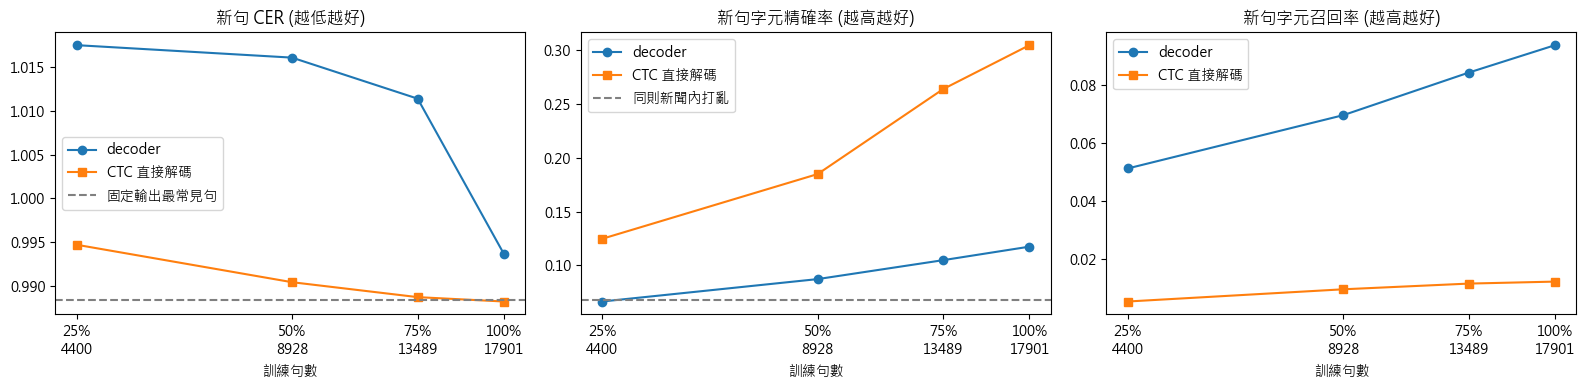


資料從 50% 加倍到 100%：decoder 新句精確率 +0.030、新句 CER 改善 +0.022
(只跑一次，單一組別的差距在 ±0.01 左右可能只是隨機誤差；看整條曲線的趨勢比看單一數字可靠)


In [10]:
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft JhengHei", "Noto Sans CJK TC", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

rows = []
for frac, run in sorted(runs.items()):
    dec = evaluate(run["decoder"], run["train"], verbose=False)
    ctc = evaluate(run["ctc"], run["train"], verbose=False)
    rows.append((frac, run["info"], dec, ctc))

cols = ["影片數", "句數", "最佳epoch", "val翻譯損失", "新句CER", "新句精確率", "新句召回率", "CTC精確率", "CTC召回率"]
print(table_row("資料量", cols, label_width=8, width=12))
for frac, info, dec, ctc in rows:
    print(table_row(f"{frac:.0%}", [
        str(info["videos"]), str(info["sentences"]),
        "-" if info["best_epoch"] is None else str(info["best_epoch"]),
        "-" if info["best_val_ce"] is None else info["best_val_ce"],
        dec["cer_new"], dec["prf_new"][0], dec["prf_new"][1], ctc["prf_new"][0], ctc["prf_new"][1],
    ], label_width=8, width=12))
print(f"\n基準：固定輸出最常見句 CER = {rows[-1][2]['base_const']:.3f}；"
      f"同則新聞內打亂的精確率 = {rows[-1][2]['prf_shuffle_clip'][0]:.3f}")

n = [info["sentences"] for _, info, _, _ in rows]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(n, [d["cer_new"] for _, _, d, _ in rows], "o-", label="decoder")
axes[0].plot(n, [c["cer_new"] for _, _, _, c in rows], "s-", label="CTC 直接解碼")
axes[0].axhline(rows[-1][2]["base_const"], color="gray", ls="--", label="固定輸出最常見句")
axes[0].set_title("新句 CER (越低越好)")
axes[1].plot(n, [d["prf_new"][0] for _, _, d, _ in rows], "o-", label="decoder")
axes[1].plot(n, [c["prf_new"][0] for _, _, _, c in rows], "s-", label="CTC 直接解碼")
axes[1].axhline(rows[-1][2]["prf_shuffle_clip"][0], color="gray", ls="--", label="同則新聞內打亂")
axes[1].set_title("新句字元精確率 (越高越好)")
axes[2].plot(n, [d["prf_new"][1] for _, _, d, _ in rows], "o-", label="decoder")
axes[2].plot(n, [c["prf_new"][1] for _, _, _, c in rows], "s-", label="CTC 直接解碼")
axes[2].set_title("新句字元召回率 (越高越好)")
for ax in axes:
    ax.set_xlabel("訓練句數")
    ax.set_xscale("log", base=2)
    ax.set_xticks(n, [f"{f:.0%}\n{s}" for (f, *_), s in zip(rows, n)])
    ax.minorticks_off()
    ax.legend()
plt.tight_layout()
plt.show()

# 粗估：每多一倍資料，decoder 新句精確率提高多少
half = [r for r in rows if abs(r[0] - 0.5) < 1e-9]
if half and rows[-1][0] == 1.0:
    gain = rows[-1][2]["prf_new"][0] - half[0][2]["prf_new"][0]
    gain_cer = half[0][2]["cer_new"] - rows[-1][2]["cer_new"]
    print(f"\n資料從 50% 加倍到 100%：decoder 新句精確率 {gain:+.3f}、新句 CER 改善 {gain_cer:+.3f}")
    print("(只跑一次，單一組別的差距在 ±0.01 左右可能只是隨機誤差；看整條曲線的趨勢比看單一數字可靠)")

## 怎麼解讀

| 曲線的樣子 | 代表什麼 | 建議 |
|---|---|---|
| 從 25% 到 100% **一路明顯改善**，到 100% 還沒變平 | 資料量是瓶頸 | 值得去找更多手語新聞影片；可以用曲線的斜率粗估資料加倍大約會再進步多少 |
| 前段改善、**50% 之後就變平** | 同類資料已經接近飽和 | 再加資料效果有限，優先處理特徵 (臉部、嘴型) 或縮小任務範圍 |
| **幾乎一條平線** | 模型根本沒從資料中學到可以推廣的東西 | 增加資料大概也沒用，問題在特徵或任務設定 |

橫軸是以 2 為底的對數刻度：每往右一格就是資料加倍。這種圖上，如果點大致排成一條斜直線，代表「每加倍一次資料，效果大約進步固定的量」，可以用來外推。